# Weather Hazard Category (WHC) — 05 Evaluation & Model Export

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Final Model Diagnostics (Holdout Test 2025)


In [1]:
import sys
import json
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import WHC_MODELS_DIR, WHC_CLASSES
from src.model_experiments import prepare_datasets

model = joblib.load(WHC_MODELS_DIR / "model.joblib")
with open(WHC_MODELS_DIR / "metadata.json") as f:
    meta = json.load(f)

print(f"Deployed Model: {meta['algorithm']}")
print("Test Performance:", meta["performance_metrics"])


Deployed Model: Random Forest Classifier
Test Performance: {'accuracy': 0.5503, 'balanced_accuracy': 0.2865, 'macro_f1': 0.2783, 'weighted_f1': 0.5344}


## 2. Confusion Matrix (Holdout Test 2025)

2026-09-07 16:59:06,555 - INFO - Temporal Split -> Train: 2191 rows (2018-01-01 to 2023-12-31) | Val: 366 rows (2024-01-01 to 2024-12-31) | Test: 365 rows (2025-01-01 to 2025-12-31)


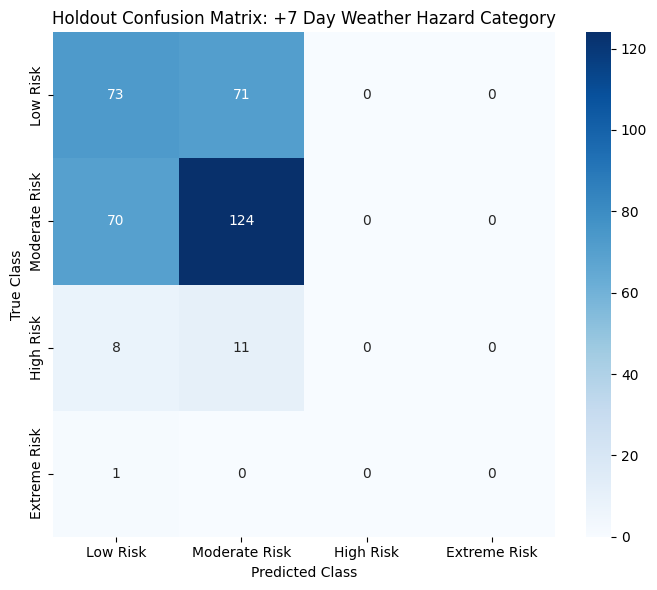

In [2]:
df, train_df, val_df, test_df, feature_cols = prepare_datasets()
ts = test_df.dropna(subset=["target_whc_h7"]).copy()
X_test = ts[feature_cols].fillna(train_df[feature_cols].median())
y_test = ts["target_whc_h7"].astype(int)

preds = model.predict(X_test)
cm = confusion_matrix(y_test, preds, labels=[0, 1, 2, 3])

labels = ["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"]
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Holdout Confusion Matrix: +7 Day Weather Hazard Category")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig("reports/figures/whc_confusion_matrix.png", dpi=150)
plt.show()


## 3. Classification Report

In [3]:
print(classification_report(y_test, preds, target_names=labels[:len(np.unique(y_test))], zero_division=0))


               precision    recall  f1-score   support

     Low Risk       0.48      0.51      0.49       144
Moderate Risk       0.60      0.64      0.62       194
    High Risk       0.00      0.00      0.00        19
 Extreme Risk       0.00      0.00      0.00         1

     accuracy                           0.55       358
    macro avg       0.27      0.29      0.28       358
 weighted avg       0.52      0.55      0.53       358



## 4. Top Feature Importances

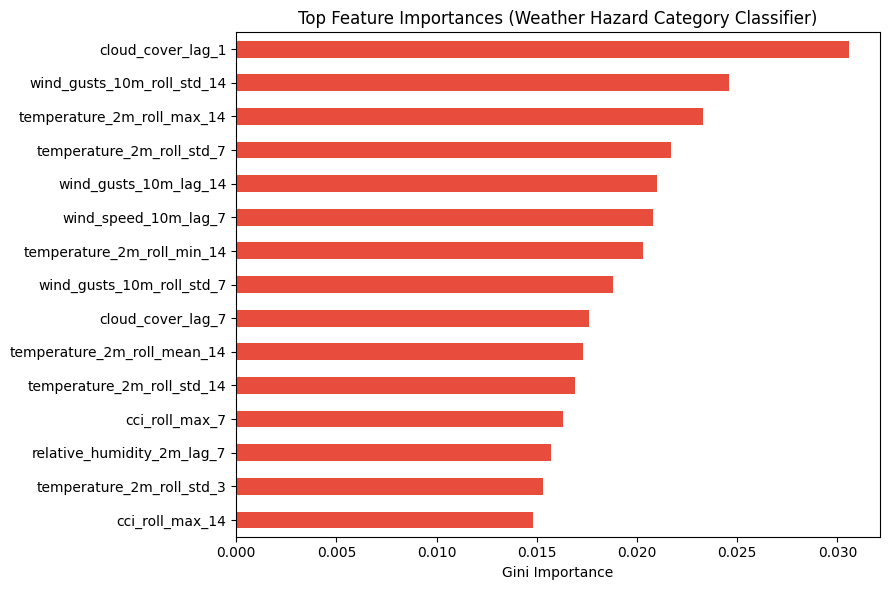

In [4]:
fi_series = pd.Series(meta["feature_importance"]).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
fi_series.plot(kind="barh", color="#e74c3c")
plt.title("Top Feature Importances (Weather Hazard Category Classifier)")
plt.xlabel("Gini Importance")
plt.tight_layout()
plt.savefig("reports/figures/whc_feature_importance.png", dpi=150)
plt.show()


## 5. Summary & Deployment Artefacts
The final trained classifier and metadata are stored in `models/weather_hazard/`:
- `model.joblib`
- `metadata.json`
